## Team
- Rey Sioson
- Cohen Kang

## Problem Statement
This project will predict whether a bank customer **leaves or stays**, using customer and account information. Identifying customers who may leave could help a bank decide where to focus retention efforts.


## Dataset
We plan to use Kaggle's public **Churn Modelling** dataset.

| Property | Details |
|---|---|
| Size | 10,000 rows × 14 columns |
| Predictors | 10 substantive customer/account predictors |
| Identifier-like columns | `RowNumber`, `CustomerId`, `Surname` |
| Target | `Exited` (1 = left, 0 = stayed) |
| Churners | 2,037 (20.37%) |
| Non-churners | 7,963 (79.63%) |
| Class ratio | ≈ 3.9 non-churners per churner |
| Missing values | Reported to have none |

In [4]:
# imports
import pandas as pd
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

# Load the Churn_Modelling.xls dataset
df = pd.read_csv("Churn_Modelling.xls")
#summary of its actual shape, feature types, missing values, and class distribution
for i in range(1, 6):
    print(f"Row {i}: {df.iloc[i].values}")
print("\nDataset shape:", df.shape)
print("Feature types:\n", df.dtypes)
print("Missing values:\n", df.isnull().sum())
print("Class distribution:\n", df['Exited'].value_counts())


Row 1: [np.int64(2) np.int64(15647311) 'Hill' np.int64(608) 'Spain' 'Female'
 np.int64(41) np.int64(1) np.float64(83807.86) np.int64(1) np.int64(0)
 np.int64(1) np.float64(112542.58) np.int64(0)]
Row 2: [np.int64(3) np.int64(15619304) 'Onio' np.int64(502) 'France' 'Female'
 np.int64(42) np.int64(8) np.float64(159660.8) np.int64(3) np.int64(1)
 np.int64(0) np.float64(113931.57) np.int64(1)]
Row 3: [np.int64(4) np.int64(15701354) 'Boni' np.int64(699) 'France' 'Female'
 np.int64(39) np.int64(1) np.float64(0.0) np.int64(2) np.int64(0)
 np.int64(0) np.float64(93826.63) np.int64(0)]
Row 4: [np.int64(5) np.int64(15737888) 'Mitchell' np.int64(850) 'Spain' 'Female'
 np.int64(43) np.int64(2) np.float64(125510.82) np.int64(1) np.int64(1)
 np.int64(1) np.float64(79084.1) np.int64(0)]
Row 5: [np.int64(6) np.int64(15574012) 'Chu' np.int64(645) 'Spain' 'Male'
 np.int64(44) np.int64(8) np.float64(113755.78) np.int64(2) np.int64(1)
 np.int64(0) np.float64(149756.71) np.int64(1)]

Dataset shape: (10000,

In [48]:
# define features and target variable
X = df.drop(columns=["Exited", "RowNumber", "CustomerId", "Surname"])  # Features (all columns except: Exited, RowNumber, CustomerId, and Surname, which are not relevant for prediction)
y = df["Exited"]  # Target variable ('Exited')
# one-hot encode categorical columns
X = pd.get_dummies(X, columns=["Geography", "Gender"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split( #split the dataset with test_size=0.2
    X,
    y,
    test_size=0.20,
    train_size=0.80,
    stratify=y,
    random_state=42,
)

# scale: fit on train only, then apply to test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Planned Methods

| Model | Rationale |
|---|---|
| **Baseline: majority-class classifier** | Predicting "stayed" for every customer gives a simple reference point and shows why accuracy alone can be misleading here. |
| **Logistic regression** | A straightforward, interpretable model that provides a useful comparison for binary classification. |
| **Decision tree** | Can capture nonlinear patterns and interactions, and its decision rules are relatively easy to inspect. |
| **Random forest** | Combines many trees, which can improve predictive performance and reduce overfitting compared with a single decision tree. |

## Evaluation Plan
- **Data split:** Use a **stratified train/test split** to preserve the class ratio, and keep the test set out of model selection.
- **Metrics:** Compare recall, precision, F1, ROC, accuracy, and the confusion matrix.
  - **Recall** – how many actual churners are found.
  - **Precision** – how often a churn prediction is correct.
  - **F1** – balances precision and recall.
- **Accuracy caveat:** Because churners are only 20.37% of the data, we will **not** rely on accuracy alone.
- **Tuning:** If tuning the decision threshold or using class weights, do so with cross-validation on the training data.

In [49]:
# baseline majority class model using DummyClassifier
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
print("Baseline accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.7965
[[1593    0]
 [ 407    0]]
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1593
           1       0.00      0.00      0.00       407

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.63      0.80      0.71      2000



In [50]:
# logistic regression model

log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
log_reg.fit(X_train_s, y_train)

y_pred = log_reg.predict(X_test_s)
y_prob = log_reg.predict_proba(X_test_s)[:, 1]   # churn probabilities, for ROC

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

fpr, tpr, _ = roc_curve(y_test, y_prob)
print("ROC AUC:", auc(fpr, tpr))


[[1142  451]
 [ 122  285]]
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

ROC AUC: 0.7771376923919298


In [51]:
# decision tree model

dt = DecisionTreeClassifier(class_weight="balanced", random_state=42)
dt.fit(X_train_s, y_train)
print("Train Accuracy:", accuracy_score(y_train, dt.predict(X_train_s)))
pred = dt.predict(X_test_s)
accuracy = accuracy_score(y_test, pred)
print("Base Decision Tree Test Accuracy:", accuracy)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, dt.predict_proba(X_test_s)[:, 1]))


Train Accuracy: 1.0
Base Decision Tree Test Accuracy: 0.7715
[[1356  237]
 [ 220  187]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1593
           1       0.44      0.46      0.45       407

    accuracy                           0.77      2000
   macro avg       0.65      0.66      0.65      2000
weighted avg       0.78      0.77      0.77      2000

ROC AUC: 0.6553417824604265


In [52]:
# explore how max-depth parameter affects decision tree performance
depth_search = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"max_depth": list(range(1, 21))},
    scoring="f1", cv=5,
)
depth_search.fit(X_train_s, y_train)
print("Best max_depth:", depth_search.best_params_["max_depth"])

dt_depth = depth_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, dt_depth.predict(X_train_s)))
pred = dt_depth.predict(X_test_s)
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, dt_depth.predict_proba(X_test_s)[:, 1]))


Best max_depth: 6
Train Accuracy: 0.775875
Test Accuracy: 0.7585
[[1204  389]
 [  94  313]]
              precision    recall  f1-score   support

           0       0.93      0.76      0.83      1593
           1       0.45      0.77      0.56       407

    accuracy                           0.76      2000
   macro avg       0.69      0.76      0.70      2000
weighted avg       0.83      0.76      0.78      2000

ROC AUC: 0.8331783247037485


In [53]:
# post-pruning: grow the full tree, then cut back branches using ccp_alpha
path = DecisionTreeClassifier(class_weight="balanced", random_state=42).cost_complexity_pruning_path(X_train_s, y_train)
ccp_alphas = path.ccp_alphas[:-1]   # drop last alpha because it prunes to just the root
alpha_grid = np.unique(np.quantile(ccp_alphas, np.linspace(0, 1, 40)))  # narrow down all alpha values to ~40 evenly spread values

# find best alpha value using GridSearchCV with 5-fold cross-validation and f1 score as the metric
alpha_search = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"ccp_alpha": alpha_grid},
    scoring="f1", cv=5,
)
alpha_search.fit(X_train_s, y_train)
print("Best ccp_alpha:", alpha_search.best_params_["ccp_alpha"])

dt_post = alpha_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, dt_post.predict(X_train_s)))
pred = dt_post.predict(X_test_s)
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, dt_post.predict_proba(X_test_s)[:, 1]))


Best ccp_alpha: 0.0010622255798546272
Train Accuracy: 0.771375
Test Accuracy: 0.761
[[1205  388]
 [  90  317]]
              precision    recall  f1-score   support

           0       0.93      0.76      0.83      1593
           1       0.45      0.78      0.57       407

    accuracy                           0.76      2000
   macro avg       0.69      0.77      0.70      2000
weighted avg       0.83      0.76      0.78      2000

ROC AUC: 0.852423301575844


In [54]:
# random forest model

# base random forest (default settings) to compare against the single decision tree
# n_jobs=-1 use all available CPU cores for parallel processing
rf = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train_s, y_train)
print("Base RF Train Accuracy:", accuracy_score(y_train, rf.predict(X_train_s)))
print("Base RF Test Accuracy:", accuracy_score(y_test, rf.predict(X_test_s)))
print(confusion_matrix(y_test, rf.predict(X_test_s)))
print(classification_report(y_test, rf.predict(X_test_s)))
print("Base RF ROC AUC:", roc_auc_score(y_test, rf.predict_proba(X_test_s)[:, 1]))

# tune the forest with GridSearchCV (5-fold CV, f1 score), same approach as the decision tree
rf_search = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    {
        "n_estimators": [100, 300],          # number of trees
        "max_depth": [6, 8, 10, None],       # limit tree depth to reduce overfitting
        "min_samples_leaf": [1, 5],          # minimum samples required in a leaf
    },
    scoring="f1", cv=5,
)
rf_search.fit(X_train_s, y_train)
print("Best params:", rf_search.best_params_)

rf_best = rf_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, rf_best.predict(X_train_s)))
pred = rf_best.predict(X_test_s)
y_prob = rf_best.predict_proba(X_test_s)[:, 1]   # churn probabilities, for ROC
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))


Base RF Train Accuracy: 1.0
Base RF Test Accuracy: 0.86
[[1542   51]
 [ 229  178]]
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.78      0.44      0.56       407

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.74      2000
weighted avg       0.85      0.86      0.84      2000

Base RF ROC AUC: 0.8508354271066135
Best params: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
Train Accuracy: 0.925625
Test Accuracy: 0.8445
[[1430  163]
 [ 148  259]]
              precision    recall  f1-score   support

           0       0.91      0.90      0.90      1593
           1       0.61      0.64      0.62       407

    accuracy                           0.84      2000
   macro avg       0.76      0.77      0.76      2000
weighted avg       0.85      0.84      0.85      2000

ROC AUC: 0.8637697790240162


In [ ]:
# bagging model
# bagging trains many decision trees, each on a bootstrap sample (random sample with replacement) of the training data,
# and averages their votes. 
# A random forest is bagging plus a random subset of features at each split, so comparing the two shows 
# what that extra feature randomness adds.
bag_search = GridSearchCV(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(class_weight="balanced", random_state=42),
        random_state=42, n_jobs=-1,
    ),
    {
        "n_estimators": [100, 300],                   # number of trees
        "estimator__max_depth": [6, 8, 10, None],     # same depth/leaf grid as the random forest
        "estimator__min_samples_leaf": [1, 5],
    },
    scoring="f1", cv=5,
)
bag_search.fit(X_train_s, y_train)
print("Best params:", bag_search.best_params_)

bag_best = bag_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, bag_best.predict(X_train_s)))
pred = bag_best.predict(X_test_s)
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, bag_best.predict_proba(X_test_s)[:, 1]))

Best params: {'estimator__max_depth': None, 'estimator__min_samples_leaf': 5, 'n_estimators': 300}
Train Accuracy: 0.943375
Test Accuracy: 0.85
[[1448  145]
 [ 155  252]]
              precision    recall  f1-score   support

           0       0.90      0.91      0.91      1593
           1       0.63      0.62      0.63       407

    accuracy                           0.85      2000
   macro avg       0.77      0.76      0.77      2000
weighted avg       0.85      0.85      0.85      2000

ROC AUC: 0.8509025203940459


In [56]:
# AdaBoost model
# boosting builds small trees one after another; each new tree gives more weight to the rows the previous trees got wrong
ada_search = GridSearchCV(
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(class_weight="balanced", random_state=42),
        random_state=42,
    ),
    {
        "n_estimators": [100, 300],                   # number of boosting rounds
        "learning_rate": [0.05, 0.1, 0.5, 1.0],       # how much each new tree contributes
        "estimator__max_depth": [1, 2, 3],            # boosting works best with shallow trees
    },
    scoring="f1", cv=5,
)
ada_search.fit(X_train_s, y_train)
print("Best params:", ada_search.best_params_)

ada_best = ada_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, ada_best.predict(X_train_s)))
pred = ada_best.predict(X_test_s)
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, ada_best.predict_proba(X_test_s)[:, 1]))

Best params: {'estimator__max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 100}
Train Accuracy: 0.789
Test Accuracy: 0.784
[[1274  319]
 [ 113  294]]
              precision    recall  f1-score   support

           0       0.92      0.80      0.86      1593
           1       0.48      0.72      0.58       407

    accuracy                           0.78      2000
   macro avg       0.70      0.76      0.72      2000
weighted avg       0.83      0.78      0.80      2000

ROC AUC: 0.8380121261477194


In [ ]:
# XGBoost model
# gradient boosting: each new tree is fit to the remaining errors of the trees before it, with built-in regularization
# XGBoost has no class_weight, so scale_pos_weight handles the class imbalance instead
neg, pos = np.bincount(y_train)
xgb_search = GridSearchCV(
    xgb.XGBClassifier(scale_pos_weight=neg / pos, eval_metric="logloss", random_state=42, n_jobs=-1),
    {
        "n_estimators": [100, 300],                   # number of boosting rounds
        "max_depth": [3, 4, 6],                       # depth of each tree
        "learning_rate": [0.05, 0.1],                 # how much each new tree contributes
    },
    scoring="f1", cv=5,
)
xgb_search.fit(X_train_s, y_train)
print("Best params:", xgb_search.best_params_)

xgb_best = xgb_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, xgb_best.predict(X_train_s)))
pred = xgb_best.predict(X_test_s)
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, xgb_best.predict_proba(X_test_s)[:, 1]))

Best params: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 300}
Train Accuracy: 0.905
Test Accuracy: 0.8155
[[1350  243]
 [ 126  281]]
              precision    recall  f1-score   support

           0       0.91      0.85      0.88      1593
           1       0.54      0.69      0.60       407

    accuracy                           0.82      2000
   macro avg       0.73      0.77      0.74      2000
weighted avg       0.84      0.82      0.82      2000

ROC AUC: 0.8490231371587302


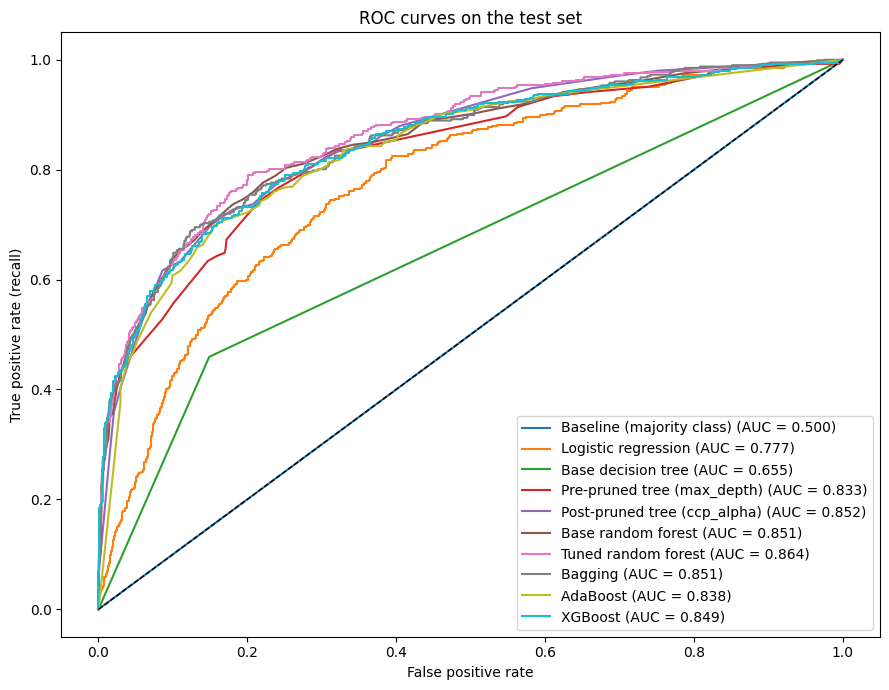

In [58]:
# ROC curves for every model on the test set
models = {
    "Baseline (majority class)": (baseline, X_test),
    "Logistic regression": (log_reg, X_test_s),
    "Base decision tree": (dt, X_test_s),
    "Pre-pruned tree (max_depth)": (dt_depth, X_test_s),
    "Post-pruned tree (ccp_alpha)": (dt_post, X_test_s),
    "Base random forest": (rf, X_test_s),
    "Tuned random forest": (rf_best, X_test_s),
    "Bagging": (bag_best, X_test_s),
    "AdaBoost": (ada_best, X_test_s),
    "XGBoost": (xgb_best, X_test_s),
}

plt.figure(figsize=(9, 7))
for name, (model, X_eval) in models.items():
    probs = model.predict_proba(X_eval)[:, 1]   # churn probabilities
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1)   # random-guess reference line
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Tree and Ensemble Model Comparison

Settings chosen by 5-fold CV on F1:
- **Pre-pruned tree:** `max_depth=6`
- **Post-pruned tree:** `ccp_alpha≈0.0011`
- **Tuned random forest:** `n_estimators=100`, `max_depth=None`, `min_samples_leaf=5`
- **Bagging:** `n_estimators=300`, base tree `max_depth=None`, `min_samples_leaf=5`
- **AdaBoost:** `n_estimators=100`, `learning_rate=0.1`, base tree `max_depth=3`
- **XGBoost:** `n_estimators=300`, `learning_rate=0.05`, `max_depth=6`

| Metric | Base Tree | Pre-pruned Tree | Post-pruned Tree | Base Random Forest | Tuned Random Forest | Bagging | AdaBoost | XGBoost |
|---|---|---|---|---|---|---|---|---|
| Train accuracy | 1.000 | 0.776 | 0.771 | 1.000 | 0.926 | 0.943 | 0.789 | 0.905 |
| Test accuracy | 0.772 | 0.759 | 0.761 | **0.860** | 0.845 | 0.850 | 0.784 | 0.816 |
| Generalization Error | 0.228 | 0.017 | 0.010 | 0.140 | 0.081 | 0.093 | **0.005** | 0.089 |
| Precision (churn = 1) | 0.44 | 0.45 | 0.45 | **0.78** | 0.61 | 0.63 | 0.48 | 0.54 |
| Recall (churn = 1) | 0.46 | 0.77 | **0.78** | 0.44 | 0.64 | 0.62 | 0.72 | 0.69 |
| F1 (churn = 1) | 0.45 | 0.56 | 0.57 | 0.56 | 0.62 | **0.63** | 0.58 | 0.60 |
| Precision (stayed = 0) | 0.86 | **0.93** | **0.93** | 0.87 | 0.91 | 0.90 | 0.92 | 0.91 |
| Recall (stayed = 0) | 0.85 | 0.76 | 0.76 | **0.97** | 0.90 | 0.91 | 0.80 | 0.85 |
| F1 (stayed = 0) | 0.86 | 0.83 | 0.83 | **0.92** | 0.90 | 0.91 | 0.86 | 0.88 |
| Macro avg F1 | 0.65 | 0.70 | 0.70 | 0.74 | 0.76 | **0.77** | 0.72 | 0.74 |
| ROC AUC | 0.655 | 0.833 | 0.852 | 0.851 | **0.864** | 0.851 | 0.838 | 0.849 |

- The **base tree** overfits: it scores 100% on training data but only 77.2% on the test set, and it finds fewer than half of the churners (recall 0.46).
- **Pre-pruning** with `max_depth=6` lowers test accuracy slightly (0.772 → 0.759) but shrinks the generalization error from 0.228 to 0.017 and raises churn recall from 0.46 to 0.77 (churn F1 0.45 → 0.56).
- **Post-pruning** with `ccp_alpha` generalizes well (gap 0.010), finds the most churners of any model (recall 0.78), and has the best churn F1 (0.57) and ROC AUC (0.852) of the single trees. Like the pre-pruned tree, its churn precision is low (0.45).
- The **base random forest** has the highest test accuracy (0.860) and churn precision (0.78), even though each of its trees is fully grown, because averaging many trees reduces overfitting. However, it finds only 44% of churners, which shows why accuracy alone is misleading here.
- The **tuned random forest** (100 trees, no depth limit, `min_samples_leaf=5`) has the highest ROC AUC (0.864) and a good precision/recall balance (0.61 / 0.64). It trades some recall relative to the pruned trees (0.64 vs. 0.77–0.78) for higher precision (0.61 vs. 0.45).
- **Bagging** (300 trees, no depth limit, `min_samples_leaf=5`) ends up almost identical to the tuned random forest. It has a slightly higher churn F1 (0.63 vs. 0.62) and macro F1 (0.77 vs. 0.76), but a lower ROC AUC (0.851 vs. 0.864).
- **AdaBoost** (100 rounds of depth-3 trees) generalizes best of all the models (train−test gap 0.005) and has high churn recall (0.72), but its churn precision (0.48) is close to the pruned trees', so its churn F1 (0.58) is only slightly better.
- **XGBoost** (300 rounds, depth 6, learning rate 0.05) lands between AdaBoost and the forests: churn recall 0.69, precision 0.54, F1 0.60, and ROC AUC 0.849. 
- Pruning, tuning, and ensembling improve churn recall and F1 even when test accuracy stays flat or drops slightly, so accuracy alone would hide most of the improvement.

**ROC curves:** In the ROC plot above, the tuned random forest has the highest AUC (0.864). It leads the post-pruned tree (0.852), base random forest (0.851), bagging (0.851), XGBoost (0.849), and AdaBoost (0.838) by only about 0.01–0.03. A gap this small could easily come from random variation in the 2,000-customer test set. That isn't enough on its own to say the random forest is the better choice for this churn problem: bagging, for example, has a slightly higher churn F1. Every model except the unpruned base tree beats logistic regression (AUC 0.777).

## Risks

| Risk | Mitigation |
|---|---|
| The dataset may be too small or unrepresentative to support conclusions about real-world bank customers. | Present findings as a comparison **on this dataset only**; if reliable generalization is not possible, report that limitation rather than overstate results. |
| Identifier-like fields could introduce misleading patterns if included. | Inspect and exclude non-informative identifiers (`RowNumber`, `CustomerId`, `Surname`). |
| Class imbalance may lead a model to miss churners while still achieving high accuracy. | Use `class_weight="balanced"` and judge models on churn recall, precision, F1, and ROC AUC rather than accuracy alone. |